** Phase 1:Intialize the environment
- As States and Actions
Alpha>>learning rate
Gamma>>Discount factor
episodes>>number of training **



In [1]:
# State space
states = ["Cold", "Comfortable", "Hot"]

# Action space
HEATER_ON = 0
HEATER_OFF = 1

actions = [HEATER_ON, HEATER_OFF]

# Initial state
initial_state = "Cold"

# Learning parameters
alpha = 0.1
gamma = 0.9
episodes = 500

**Write Transition function as a code according to the table**

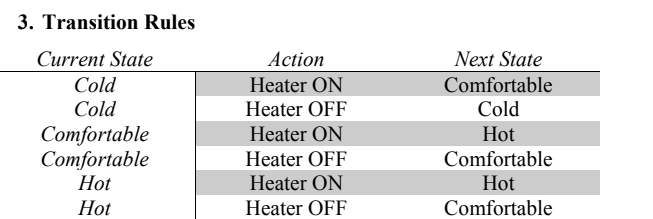

In [2]:
def transition(state, action):
    if state == "Cold":
        if action == HEATER_ON:
            return "Comfortable"
        else:
            return "Cold"

    elif state == "Comfortable":
        if action == HEATER_ON:
            return "Hot"
        else:
            return "Comfortable"

    elif state == "Hot":
        if action == HEATER_ON:
            return "Hot"
        else:
            return "Comfortable"

**Writing RewardFunction**

In [3]:
def reward_function(next_state):
    if next_state == "Comfortable":
        return 10
    elif next_state == "Hot":
        return -5
    elif next_state == "Cold":
        return -1

**Testing the environment**

In [4]:
next_state = transition("Cold", HEATER_ON)
reward = reward_function(next_state)

print("Next state:", next_state)
print("Reward:", reward)

Next state: Comfortable
Reward: 10


In [7]:
print("Environment Testing:\n")

for state in states:
    for action in actions:
        next_state = transition(state, action)
        reward = reward_function(next_state)

        action_name = "ON" if action == HEATER_ON else "OFF"

        print(
            f"State: {state}, "
            f"Action: {action_name}, "
            f"Next State: {next_state}, "
            f"Reward: {reward}"
        )

Environment Testing:

State: Cold, Action: ON, Next State: Comfortable, Reward: 10
State: Cold, Action: OFF, Next State: Cold, Reward: -1
State: Comfortable, Action: ON, Next State: Hot, Reward: -5
State: Comfortable, Action: OFF, Next State: Comfortable, Reward: 10
State: Hot, Action: ON, Next State: Hot, Reward: -5
State: Hot, Action: OFF, Next State: Comfortable, Reward: 10


**Intialize Q table**

In [5]:
# Initialize Q-table with zeros
Q = {}

for state in states:
    Q[state] = {}

    for action in actions:
        Q[state][action] = 0.0

print("Initial Q-table:")

for state in states:
    print(state, Q[state])

Initial Q-table:
Cold {0: 0.0, 1: 0.0}
Comfortable {0: 0.0, 1: 0.0}
Hot {0: 0.0, 1: 0.0}


In [6]:
print(Q["Cold"][HEATER_ON])
print(Q["Hot"][HEATER_OFF])

0.0
0.0


In [8]:

Q = {
    state: {action: 0.0 for action in actions}
    for state in states
}

print("Initial Q-table:")
print(f"{'State':<15} {'Heater ON':<15} {'Heater OFF':<15}")

for state in states:
    print(
        f"{state:<15} "
        f"{Q[state][HEATER_ON]:<15.1f} "
        f"{Q[state][HEATER_OFF]:<15.1f}"
    )

Initial Q-table:
State           Heater ON       Heater OFF     
Cold            0.0             0.0            
Comfortable     0.0             0.0            
Hot             0.0             0.0            


In [9]:
assert len(states) == 3
assert len(actions) == 2

assert all(
    Q[state][action] == 0.0
    for state in states
    for action in actions
)

assert initial_state == "Cold"

print("Environment and Q-table are ready!")

Environment and Q-table are ready!


**Phase2:Q-Learning Equation**